# ARIMA против классического ML на ряде продаж

**Задача.** Подобрать модель ARIMA для ряда ежемесячных продаж компании X и сравнить её прогноз с линейной регрессией и случайным лесом на лаговых признаках.

**Данные.** `../data/monthly-sales-of-company-x-jan-6.csv` — 77 месячных наблюдений (январь 1965 — май 1971), Time Series Data Library.

**План.**
1. EDA: ADF-тест, ACF/PACF, QQ-plot; логарифмирование для стабилизации дисперсии.
2. Подбор порядка ARIMA(p, d, q) перебором по AIC, диагностика остатков.
3. Честное сравнение на отложенных последних 15% ряда (12 месяцев): ARIMA обучается только на train, ML-модели — на лагах 1–24 из train; метрики MAE/RMSE в исходных единицах.

> В первой версии работы ARIMA обучалась на всём ряде, а её прогноз *за пределы выборки* сравнивался с последними 15% *внутри* выборки. Ниже это исправлено; ошибочная схема оставлена в одной ячейке только для сравнения.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.tsa.api as smt

from statsmodels.tsa.stattools import adfuller

DATA_DIR = '../data/'

In [2]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [3]:
# (вспомогательный код из учебных материалов курса)
def test_stationarity(timeseries):
    print('Результаты теста Дики-Фуллера:')
    dftest = adfuller(timeseries, autolag='AIC', result_object=False)
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for [key, value] in dftest[4].items():
        dfoutput['Critical Value (%s)' % key] = value
    print(dfoutput)

In [4]:
# (вспомогательный код из учебных материалов курса)
def tsplot(y, lags=None, figsize=(12, 8), style='bmh'):
    test_stationarity(y)
    if not isinstance(y, pd.Series):
        y = pd.Series(y)
    with plt.style.context(style):
        plt.figure(figsize=figsize)
        layout = (5, 1)
        ts_ax = plt.subplot2grid(layout, (0, 0), rowspan=2)
        acf_ax = plt.subplot2grid(layout, (2, 0))
        pacf_ax = plt.subplot2grid(layout, (3, 0))
        qq_ax = plt.subplot2grid(layout, (4, 0))

        y.plot(ax=ts_ax, color='blue', label='Or')
        ts_ax.set_title('Original')

        smt.graphics.plot_acf(y, lags=lags, ax=acf_ax, alpha=0.05)
        smt.graphics.plot_pacf(y, lags=lags, ax=pacf_ax, alpha=0.05)
        sm.qqplot(y, line='s', ax=qq_ax)

        plt.tight_layout()
    return

In [5]:
# временной ряд продаж компании X
series = pd.read_csv(DATA_DIR + "monthly-sales-of-company-x-jan-6.csv")["Count"]

Результаты теста Дики-Фуллера:
Test Statistic                  0.654715
p-value                         0.988889
#Lags Used                     12.000000
Number of Observations Used    64.000000
Critical Value (1%)            -3.536928
Critical Value (5%)            -2.907887
Critical Value (10%)           -2.591493
dtype: float64


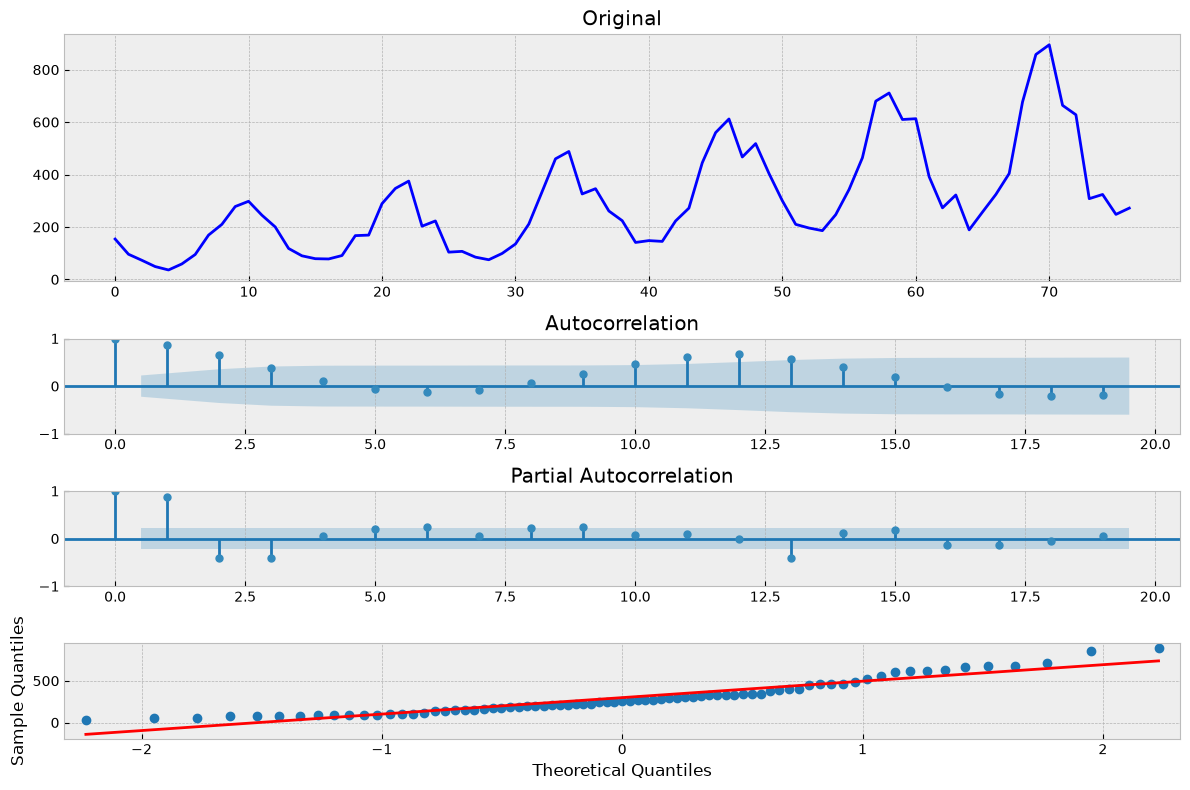

In [6]:
tsplot(series)

In [7]:
series = np.log(series) # стабилизируем дисперсию
tsplot(series)

Результаты теста Дики-Фуллера:
Test Statistic                 -0.908049
p-value                         0.785310
#Lags Used                     12.000000
Number of Observations Used    64.000000
Critical Value (1%)            -3.536928
Critical Value (5%)            -2.907887
Critical Value (10%)           -2.591493
dtype: float64


После логарифмирования ряд по-прежнему нестационарен (p-value = 0.785) — остаётся тренд, поэтому при подборе ARIMA нужен порядок интегрирования d ≥ 1.

## Подбор ARIMA на всём ряде (для анализа остатков)

In [8]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_predict

In [9]:
# Перебор параметров ARIMA(p, d, q)
best_aic = np.inf
best_order = None
best_mdl = None

for i in range(5):       # p
    for d in range(5):   # d
        for j in range(5):  # q
            try:
                tmp_mdl = ARIMA(series, order=(i, d, j), trend='n').fit()
                tmp_aic = tmp_mdl.aic

                if tmp_aic < best_aic:
                    best_aic = tmp_aic
                    best_order = (i, d, j)
                    best_mdl = tmp_mdl
            except:
                continue

print('aic: {:6.5f}| order: {}'.format(best_aic, best_order))

aic: -33.21456| order: (3, 1, 2)


In [10]:
mdl = ARIMA(series, order=best_order).fit()
tsplot(mdl.resid)

Результаты теста Дики-Фуллера:
Test Statistic                -32.154591
p-value                         0.000000
#Lags Used                      0.000000
Number of Observations Used    76.000000
Critical Value (1%)            -3.519481
Critical Value (5%)            -2.900395
Critical Value (10%)           -2.587498
dtype: float64


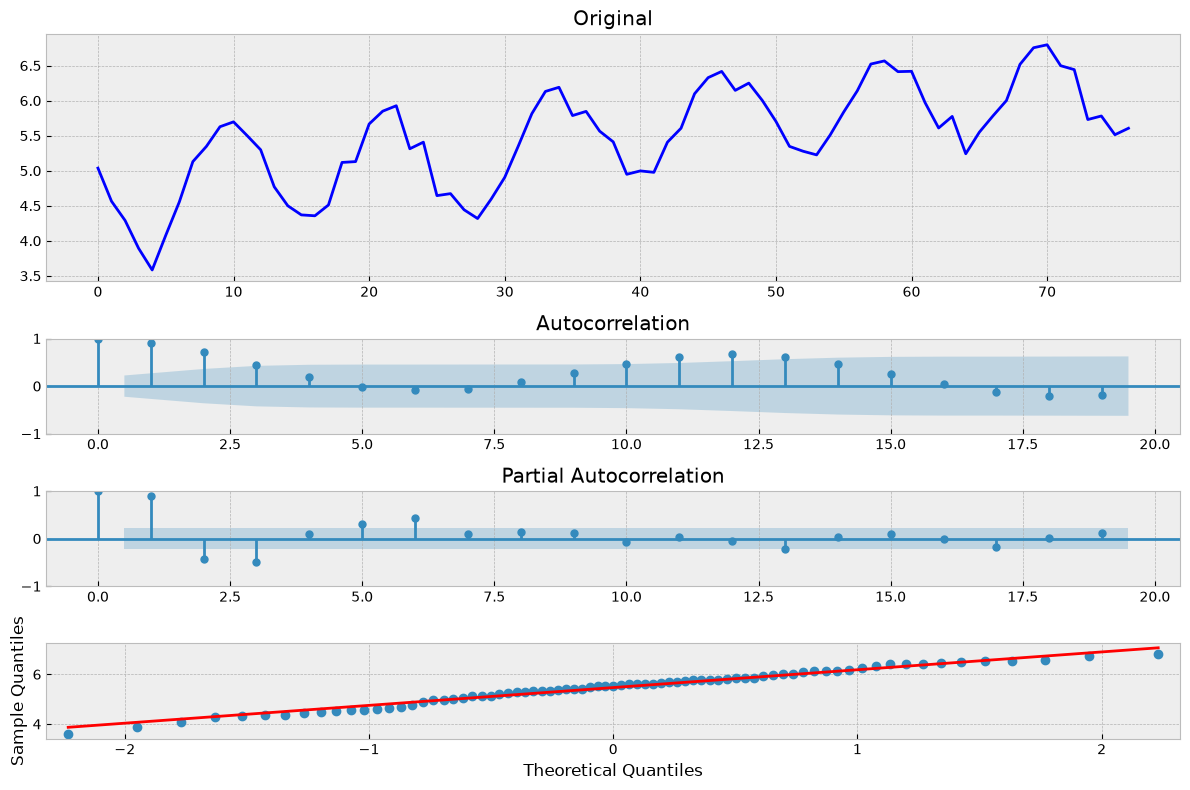

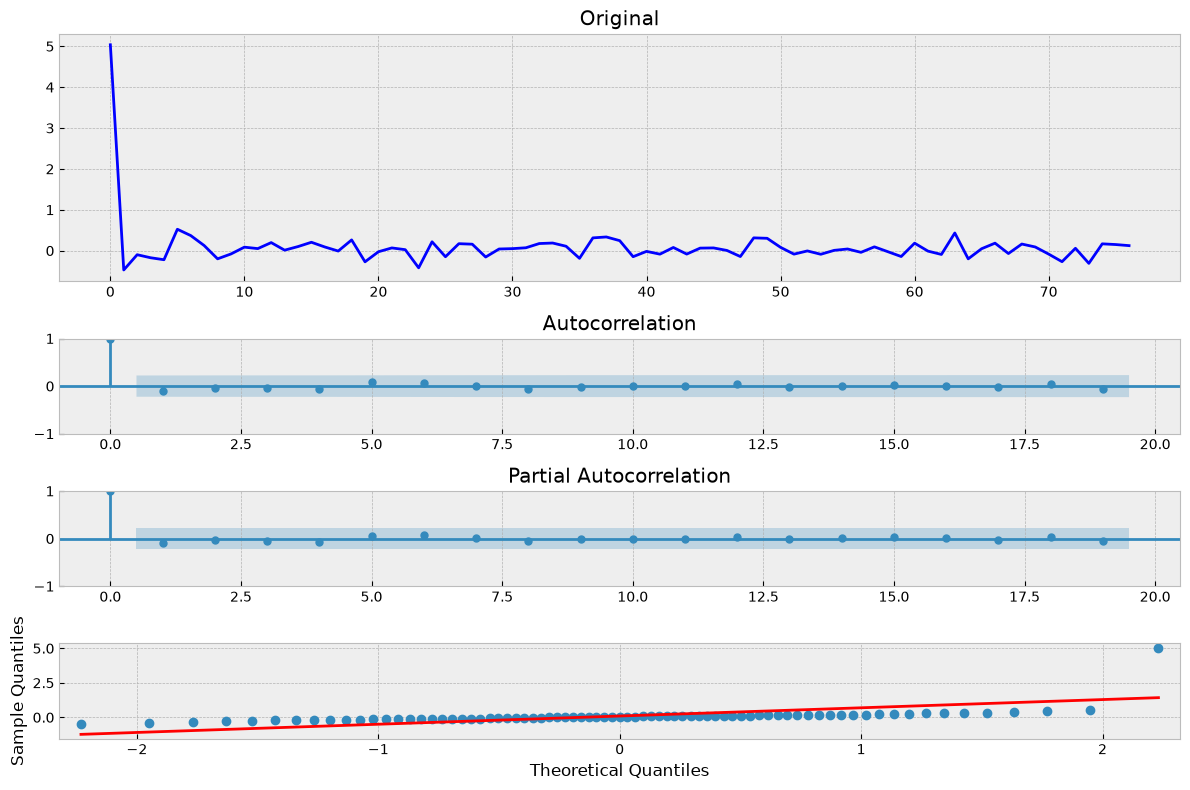

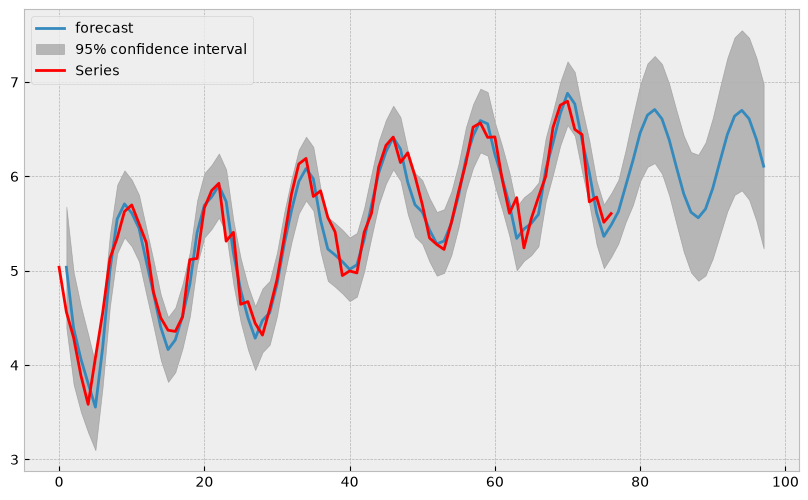

In [11]:
with plt.style.context('bmh'):
    plt.figure(figsize=(10,6))
    ax = plt.axes()
    plot_predict(mdl, 1, len(series)+20, ax=ax)
    plt.plot(series, color='red', label='Series')
    plt.legend()
    plt.show()

## Честное сравнение на отложенной выборке

Последние 15% ряда (12 месяцев) откладываются в тест. Порядок ARIMA подбирается тем же перебором по AIC, но **только на train**. Оцениваются два режима:

- **ARIMA, прогноз на 12 шагов** — один прогноз от конца train на весь тестовый горизонт;
- **ARIMA, 1 шаг вперёд** — параметры зафиксированы по train, но для прогноза каждой тестовой точки используются фактические предыдущие значения. Это тот же режим, в котором работают ML-модели (их лаговые признаки на тесте берутся из фактических данных), поэтому сравнивать с ними корректнее именно его.

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

test_size = 0.15
test_start_idx = int(len(series) * (1 - test_size))
y_train_log = series.iloc[:test_start_idx]
y_test_log = series.iloc[test_start_idx:]
print(f"Train: {len(y_train_log)} точек, test: {len(y_test_log)} точек (индексы {test_start_idx}..{len(series) - 1})")

# Тот же перебор по AIC, но только на обучающей части
best_aic_tr, best_order_tr = np.inf, None
for i in range(5):
    for d in range(5):
        for j in range(5):
            try:
                tmp_mdl = ARIMA(y_train_log, order=(i, d, j), trend='n').fit()
                if tmp_mdl.aic < best_aic_tr:
                    best_aic_tr, best_order_tr = tmp_mdl.aic, (i, d, j)
            except Exception:
                continue
print('train: aic: {:6.5f}| order: {}'.format(best_aic_tr, best_order_tr))

mdl_train = ARIMA(y_train_log, order=best_order_tr).fit()

# (а) прогноз на весь тестовый горизонт от конца train
arima_ms_log = mdl_train.get_forecast(steps=len(y_test_log)).predicted_mean
# (б) прогноз на 1 шаг вперёд: параметры с train, фильтрация по фактическим тестовым значениям
arima_1s_log = mdl_train.append(y_test_log, refit=False).predict(start=test_start_idx, end=len(series) - 1)

y_test_orig = np.exp(y_test_log)
arima_ms_orig = np.exp(arima_ms_log)
arima_1s_orig = np.exp(arima_1s_log)

Train: 65 точек, test: 12 точек (индексы 65..76)


train: aic: -25.52445| order: (3, 1, 2)


In [13]:
# Для сравнения: ошибочная схема из первой версии работы (НЕ использовать как оценку качества).
# Модель обучена на всём ряде, прогноз на 12 точек ПОСЛЕ конца ряда сравнивается с последними 12 точками ВНУТРИ ряда.
wrong_pred_orig = np.exp(mdl.get_forecast(steps=len(y_test_log)).predicted_mean)
print(f"Ошибочная схема: MAE = {mean_absolute_error(y_test_orig, wrong_pred_orig):.4f} | "
      f"RMSE = {np.sqrt(mean_squared_error(y_test_orig, wrong_pred_orig)):.4f}")

Ошибочная схема: MAE = 52.6031 | RMSE = 63.6503


## Классический ML на лаговых признаках

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [15]:
# Определяем границу тестовой выборки по ОРИГИНАЛЬНОМУ ряду (чтобы совпадало с ARIMA)
test_size = 0.15
test_start_idx = int(len(series) * (1 - test_size))

# Подготовка данных для ML
data = pd.DataFrame(series.copy())
data.columns = ['Count']

# Добавляем лаги
for i in range(1, 25):
    data[f"lag_{i}"] = data['Count'].shift(i)

data['orig_idx'] = data.index
data = data.dropna()

# Делим на train и test, ориентируясь на оригинальный индекс
X_train = data[data['orig_idx'] < test_start_idx].drop(columns=['Count', 'orig_idx'])
y_train = data[data['orig_idx'] < test_start_idx]['Count']

X_test = data[data['orig_idx'] >= test_start_idx].drop(columns=['Count', 'orig_idx'])
y_test = data[data['orig_idx'] >= test_start_idx]['Count']

print(f"Размер ML train: {X_train.shape[0]}, test: {X_test.shape[0]}")
print(f"Граница разделения (оригинальный индекс): {test_start_idx}")

Размер ML train: 41, test: 12
Граница разделения (оригинальный индекс): 65


In [16]:
# Обучение моделей
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred_log = lr.predict(X_test)

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred_log = rf.predict(X_test)

# Тестовые точки ML и ARIMA совпадают (индексы test_start_idx..конец ряда)
assert list(y_test.index) == list(y_test_log.index)

lr_pred_orig = np.exp(lr_pred_log)
rf_pred_orig = np.exp(rf_pred_log)

In [17]:
# Расчет метрик (в исходных единицах — штуки продаж)
preds = {
    f'ARIMA{best_order_tr}, 12 шагов': arima_ms_orig.values,
    f'ARIMA{best_order_tr}, 1 шаг': arima_1s_orig.values,
    'Linear Regression, 1 шаг': lr_pred_orig,
    'Random Forest, 1 шаг': rf_pred_orig,
    # бейзлайн: сезонный наивный прогноз — значение того же месяца год назад
    'Сезонный наивный (t-12)': np.exp(series.shift(12)).iloc[test_start_idx:].values,
}
results = {name: {'mae': mean_absolute_error(y_test_orig, p),
                  'rmse': np.sqrt(mean_squared_error(y_test_orig, p))} for name, p in preds.items()}

print("=" * 65)
print(f"{'Модель':<30} | {'MAE':<12} | {'RMSE':<12}")
print("-" * 65)
for model_name, metrics in results.items():
    print(f"{model_name:<30} | {metrics['mae']:<12.4f} | {metrics['rmse']:<12.4f}")
print("=" * 65)

best_model = min(results, key=lambda x: results[x]['rmse'])
print(f"Наименьшая RMSE на тестовой выборке: '{best_model}' (RMSE = {results[best_model]['rmse']:.4f})")

Модель                         | MAE          | RMSE        
-----------------------------------------------------------------
ARIMA(3, 1, 2), 12 шагов       | 101.4571     | 126.2686    
ARIMA(3, 1, 2), 1 шаг          | 80.7733      | 108.9723    
Linear Regression, 1 шаг       | 110.0283     | 146.3287    
Random Forest, 1 шаг           | 87.1612      | 116.0449    
Сезонный наивный (t-12)        | 95.4167      | 112.0874    
Наименьшая RMSE на тестовой выборке: 'ARIMA(3, 1, 2), 1 шаг' (RMSE = 108.9723)


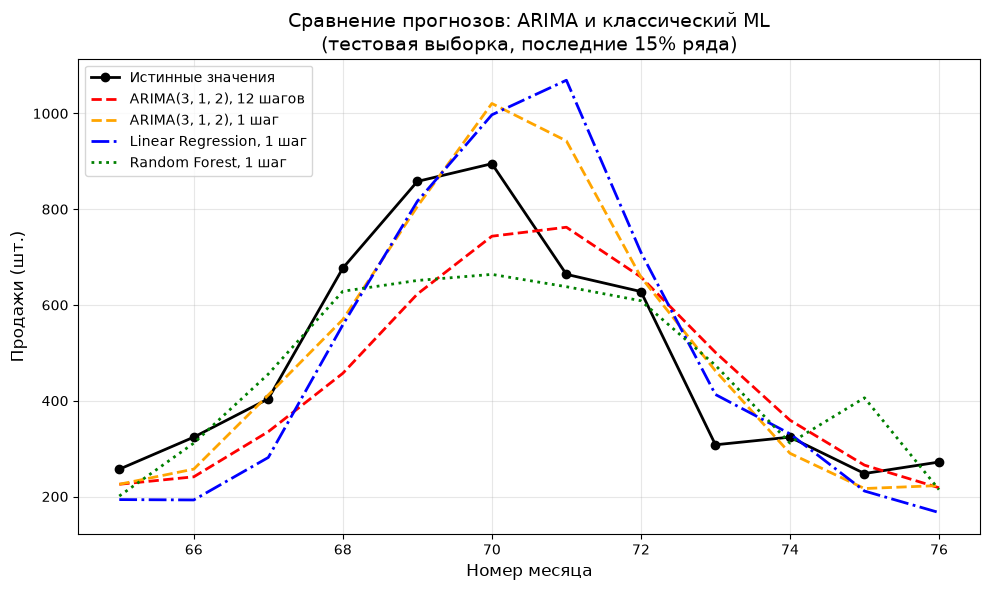

In [18]:
x_vals = y_test_log.index

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_test_orig.values, label='Истинные значения', color='black', linewidth=2, marker='o')
plt.plot(x_vals, arima_ms_orig.values, label=f'ARIMA{best_order_tr}, 12 шагов', color='red', linestyle='--', linewidth=2)
plt.plot(x_vals, arima_1s_orig.values, label=f'ARIMA{best_order_tr}, 1 шаг', color='orange', linestyle='--', linewidth=2)
plt.plot(x_vals, lr_pred_orig, label='Linear Regression, 1 шаг', color='blue', linestyle='-.', linewidth=2)
plt.plot(x_vals, rf_pred_orig, label='Random Forest, 1 шаг', color='green', linestyle=':', linewidth=2)

plt.title('Сравнение прогнозов: ARIMA и классический ML\n(тестовая выборка, последние 15% ряда)', fontsize=14)
plt.xlabel('Номер месяца', fontsize=12)
plt.ylabel('Продажи (шт.)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Итоговый вывод

| Схема оценки | Модель | MAE | RMSE |
|---|---|---|---|
| Ошибочная (первая версия) | ARIMA(3,1,2) на всём ряде | 52.60 | 63.65 |
| Исправленная, 12 шагов | ARIMA(3,1,2) на train | 101.46 | 126.27 |
| Исправленная, 1 шаг | ARIMA(3,1,2) на train | **80.77** | **108.97** |
| Исправленная, 1 шаг | Linear Regression (лаги 1–24) | 110.03 | 146.33 |
| Исправленная, 1 шаг | Random Forest (лаги 1–24) | 87.16 | 116.04 |
| Бейзлайн | Сезонный наивный (t−12) | 95.42 | 112.09 |

- **Исправленная ошибка.** В первой версии ARIMA обучалась на всём ряде, а её прогноз за пределы выборки сравнивался с последними 15% внутри выборки. Такая оценка (MAE 52.60) не имеет смысла: модель видела тестовые точки при обучении, а сравнивались значения разных месяцев. При честной схеме ошибка ARIMA примерно в 1.5–2 раза выше.
- **Сопоставимое сравнение.** ML-модели на тесте используют фактические лаги, то есть прогнозируют на 1 шаг вперёд; в том же режиме ARIMA(3,1,2) показала наименьшие MAE и RMSE. Отрыв от Random Forest (MAE 80.8 против 87.2) и от сезонного наивного прогноза (RMSE 109.0 против 112.1) невелик, а тест — всего 12 точек, поэтому преимущество ненадёжно.
- **Прогноз на 12 шагов** ARIMA(3,1,2) хуже сезонного наивного бейзлайна: у модели нет сезонной компоненты, и на длинном горизонте она сглаживает пик продаж. Логичный следующий шаг — SARIMA с периодом 12 или сезонные признаки для ML.
- **ML-модели.** Около 41 обучающего примера на 24 лаговых признака — мало: линейная регрессия переобучается и даёт фазовый сдвиг, Random Forest сглаживает пик (прогноз леса — усреднение значений из обучающей выборки).